## Improved Porrosity Classification with Physics Informed Features #
#
### Key Improvements:
# 1. **Heat Inputs Feature**: As physics informed feature
# 2. **Binary Classification** : Porosity and No porosity
# 3. **Proper SMOTE** : Applied only to training data with correct pipeline  

## 1. Import Libraries



In [10]:
# import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")   

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, RandomizedSearchCV, cross_validate
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score, roc_auc_score, roc_curve, precision_recall_fscore_support, ConfusionMatrixDisplay
from sklearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
import joblib
from time import time

# plot settings
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')

## 2. Load Data

In [3]:
df = pd.read_csv("~/Documents/PlayTime/LMD_Modelling/data/processed/processed_data.csv")  
# features and continuous target
features = ["LED_J_per_mm", "Feed"]
X = df[features].copy()
y_continuous = df["porosity_%"].copy()

print(f"features shape: {X.shape}")
print(f"continuous target shape: {y_continuous.shape}")

# porosity distribution

print("Porosity distribution:")
print(y_continuous.describe())  
print(f"\nMin: {y_continuous.min():.2f}%, Max: {y_continuous.max():.2f}%")

features shape: (89, 2)
continuous target shape: (89,)
Porosity distribution:
count    89.000000
mean      0.299607
std       0.466428
min       0.000000
25%       0.000000
50%       0.190000
75%       0.375000
max       3.285000
Name: porosity_%, dtype: float64

Min: 0.00%, Max: 3.29%


## 3. Create Binary Classificationbs Labels


----Binaty Class Distribution ----
class 0 (No Porosity (0%))): 23 samples ( 25.84%
class 1 (Has Porosity (>0%))): 66 samples ( 74.16%


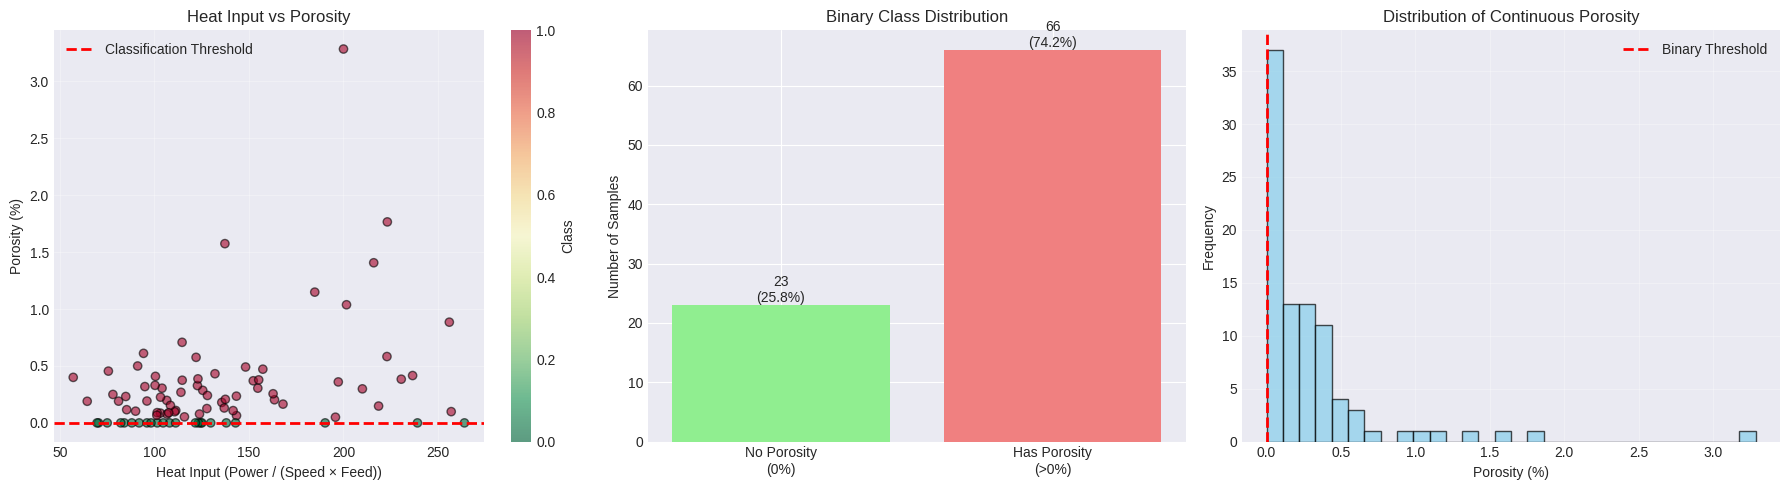


--- Train-Test Split ---
Training set size: 71 samples
Test set size: 18 samples

Training set class distribution:
porosity_%
0    18
1    53
Name: count, dtype: int64

Test set class distribution:
porosity_%
0     5
1    13
Name: count, dtype: int64


In [4]:
# Binary Classificfation - Porosity > 0% (porous) vs Porosity = 0% (non-porous)

def create_binary_label(porosity):
    """
    Create binary Label:
    -Class 0: Non-porous (porosity = 0%)
    -Class 1: Porous (porosity > 0%)
    """
    return 1 if porosity > 0 else 0 

y = y_continuous.apply(create_binary_label)

# class distribution

class_counts = y.value_counts().sort_index()
print(f"\n----Binaty Class Distribution ----")
for cls, count in class_counts.items():
    label = "No Porosity (0%)" if cls == 0 else "Has Porosity (>0%)"
    print(f"class {cls} ({label})): {count} samples ({count/len(y)*100: .2f}%")

# visualisation

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))

# Heat Input vs Porosity
scatter = ax1.scatter(df['LED_J_per_mm'], df['porosity_%'], c=y, cmap='RdYlGn_r', 
                     alpha=0.6, edgecolor='black')
ax1.set_xlabel('Heat Input (Power / (Speed × Feed))')
ax1.set_ylabel('Porosity (%)')
ax1.set_title('Heat Input vs Porosity')
ax1.axhline(y=0, color='red', linestyle='--', linewidth=2, label='Classification Threshold')
ax1.legend()
ax1.grid(True, alpha=0.3)
plt.colorbar(scatter, ax=ax1, label='Class')

# Binary class distribution
class_names = ['No Porosity\n(0%)', 'Has Porosity\n(>0%)']
bars = ax2.bar(class_names, class_counts.values, color=['lightgreen', 'lightcoral'])
ax2.set_ylabel('Number of Samples')
ax2.set_title('Binary Class Distribution')
for bar, count in zip(bars, class_counts.values):
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height,
             f'{count}\n({count/len(y)*100:.1f}%)',
             ha='center', va='bottom')

# Continuous porosity distribution with threshold
ax3.hist(y_continuous, bins=30, color='skyblue', edgecolor='black', alpha=0.7)
ax3.axvline(0, color='red', linestyle='--', linewidth=2, label='Binary Threshold')
ax3.set_xlabel('Porosity (%)')
ax3.set_ylabel('Frequency')
ax3.set_title('Distribution of Continuous Porosity')
ax3.legend()
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('binary_classification_overview.png', dpi=300, bbox_inches='tight')
plt.show()

# ## 4. Train-Test Split (Stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\n--- Train-Test Split ---")
print(f"Training set size: {X_train.shape[0]} samples")
print(f"Test set size: {X_test.shape[0]} samples")
print(f"\nTraining set class distribution:")
print(y_train.value_counts().sort_index())
print(f"\nTest set class distribution:")
print(y_test.value_counts().sort_index())

# ## 5. Model Configuration with SMOTE in Pipeline
# IMPORTANT: SMOTE is applied INSIDE cross-validation, only to training folds

In [5]:
# Stratified K-Fold CV
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {}

# --- Logistic Regression ---
lr_pipe = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(random_state=42, max_iter=1000, class_weight='balanced'))
])

lr_params = {
    'lr__C': [0.01, 0.1, 1, 10, 100],
    'lr__penalty': ['l2'],
    'smote__k_neighbors': [3, 5]  # SMOTE parameter
}

models['Logistic Regression'] = {
    'pipeline': lr_pipe,
    'params': lr_params,
    'search_type': 'grid'
}

# --- SVM (RBF Kernel) ---
svm_pipe = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', random_state=42, class_weight='balanced', probability=True))
])

svm_params = {
    'svm__C': [0.1, 1, 10, 100],
    'svm__gamma': ['scale', 'auto', 0.01, 0.1],
    'smote__k_neighbors': [3, 5]
}

models['SVM'] = {
    'pipeline': svm_pipe,
    'params': svm_params,
    'search_type': 'grid'
}

# --- Random Forest ---
rf_pipe = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('rf', RandomForestClassifier(random_state=42, class_weight='balanced'))
])

rf_params = {
    'rf__n_estimators': [100, 200, 300],
    'rf__max_depth': [None, 10, 20],
    'rf__min_samples_split': [2, 5],
    'rf__min_samples_leaf': [1, 2, 4],
    'smote__k_neighbors': [3, 5]
}

models['Random Forest'] = {
    'pipeline': rf_pipe,
    'params': rf_params,
    'search_type': 'random'
}

# --- Gradient Boosting ---
gb_pipe = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('gb', GradientBoostingClassifier(random_state=42))
])

gb_params = {
    'gb__n_estimators': [100, 200, 300],
    'gb__learning_rate': [0.01, 0.1, 0.2],
    'gb__max_depth': [3, 5, 7],
    'gb__min_samples_split': [2, 5],
    'smote__k_neighbors': [3, 5]
}

models['Gradient Boosting'] = {
    'pipeline': gb_pipe,
    'params': gb_params,
    'search_type': 'random'
}

# --- Neural Network (MLP) ---
mlp_pipe = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('scaler', StandardScaler()),
    ('mlp', MLPClassifier(random_state=42, max_iter=2000, early_stopping=True))
])

mlp_params = {
    'mlp__hidden_layer_sizes': [(50,), (100,), (50, 50)],
    'mlp__activation': ['relu', 'tanh'],
    'mlp__alpha': [0.0001, 0.001, 0.01],
    'mlp__learning_rate_init': [0.001, 0.01],
    'smote__k_neighbors': [3, 5]
}

models['Neural Network'] = {
    'pipeline': mlp_pipe,
    'params': mlp_params,
    'search_type': 'random'
}

print(f"\n--- Configured {len(models)} models ---")
print(list(models.keys()))


--- Configured 5 models ---
['Logistic Regression', 'SVM', 'Random Forest', 'Gradient Boosting', 'Neural Network']


# ## 6. Hyperparameter Tuning and Training


In [6]:
results = {}
best_models = {}

scoring = {
    'accuracy': 'accuracy',
    'f1_weighted': 'f1_weighted',
    'roc_auc': 'roc_auc',
    'precision': 'precision_weighted',
    'recall': 'recall_weighted'
}

for model_name, cfg in models.items():
    print(f"\n{'='*60}")
    print(f"Training {model_name}...")
    print(f"{'='*60}")
    start_time = time()

    if cfg['search_type'] == 'grid':
        search = GridSearchCV(
            cfg['pipeline'], cfg['params'], cv=cv, scoring=scoring,
            refit='f1_weighted', n_jobs=-1, verbose=1
        )
    else:
        search = RandomizedSearchCV(
            cfg['pipeline'], cfg['params'], cv=cv, scoring=scoring,
            refit='f1_weighted', n_iter=20, random_state=42, 
            n_jobs=-1, verbose=1
        )

    # Fit the search
    search.fit(X_train, y_train)

    best_est = search.best_estimator_
    best_models[model_name] = best_est

    # Cross-validation results
    cv_results = cross_validate(
        best_est, X_train, y_train, cv=cv, scoring=scoring,
        n_jobs=-1, return_train_score=True
    )

    # Predictions
    y_train_pred = best_est.predict(X_train)
    y_test_pred = best_est.predict(X_test)
    y_test_proba = best_est.predict_proba(X_test)[:, 1]

    # Calculate metrics
    precision, recall, f1, support = precision_recall_fscore_support(
        y_test, y_test_pred, average=None
    )

    try:
        roc_auc = roc_auc_score(y_test, y_test_proba)
    except:
        roc_auc = np.nan

    training_time = time() - start_time

    # Store results
    results[model_name] = {
        'best_params': search.best_params_,
        'accuracy_cv_mean': cv_results['test_accuracy'].mean(),
        'accuracy_cv_std': cv_results['test_accuracy'].std(),
        'f1_weighted_cv_mean': cv_results['test_f1_weighted'].mean(),
        'f1_weighted_cv_std': cv_results['test_f1_weighted'].std(),
        'accuracy_test': accuracy_score(y_test, y_test_pred),
        'precision_test_class0': precision[0],
        'recall_test_class0': recall[0],
        'f1_test_class0': f1[0],
        'precision_test_class1': precision[1],
        'recall_test_class1': recall[1],
        'f1_test_class1': f1[1],
        'roc_auc_test': roc_auc,
        'training_time_sec': training_time
    }

    print(f"\nBest parameters: {search.best_params_}")
    print(f"Training time: {training_time:.2f} seconds")
    print(f"Accuracy (CV): {results[model_name]['accuracy_cv_mean']:.4f} ± {results[model_name]['accuracy_cv_std']:.4f}")
    print(f"F1-Weighted (CV): {results[model_name]['f1_weighted_cv_mean']:.4f} ± {results[model_name]['f1_weighted_cv_std']:.4f}")
    print(f"Test Accuracy: {results[model_name]['accuracy_test']:.4f}")
    print(f"ROC-AUC (Test): {results[model_name]['roc_auc_test']:.4f}")
    print(f"F1 Score (Has Porosity): {results[model_name]['f1_test_class1']:.4f}")


Training Logistic Regression...
Fitting 5 folds for each of 10 candidates, totalling 50 fits



Best parameters: {'lr__C': 0.01, 'lr__penalty': 'l2', 'smote__k_neighbors': 3}
Training time: 3.92 seconds
Accuracy (CV): 0.7600 ± 0.0377
F1-Weighted (CV): 0.7681 ± 0.0395
Test Accuracy: 0.6667
ROC-AUC (Test): 0.8154
F1 Score (Has Porosity): 0.7000

Training SVM...
Fitting 5 folds for each of 32 candidates, totalling 160 fits

Best parameters: {'smote__k_neighbors': 3, 'svm__C': 10, 'svm__gamma': 0.01}
Training time: 1.13 seconds
Accuracy (CV): 0.7733 ± 0.0566
F1-Weighted (CV): 0.7805 ± 0.0570
Test Accuracy: 0.6667
ROC-AUC (Test): 0.8154
F1 Score (Has Porosity): 0.7273

Training Random Forest...
Fitting 5 folds for each of 20 candidates, totalling 100 fits

Best parameters: {'smote__k_neighbors': 3, 'rf__n_estimators': 200, 'rf__min_samples_split': 2, 'rf__min_samples_leaf': 4, 'rf__max_depth': 10}
Training time: 12.95 seconds
Accuracy (CV): 0.7743 ± 0.0954
F1-Weighted (CV): 0.7857 ± 0.0847
Test Accuracy: 0.6667
ROC-AUC (Test): 0.6615
F1 Score (Has Porosity): 0.7500

Training Gradient

# ## 7. Results Summary

In [7]:
results_df = pd.DataFrame(results).T

summary_cols = ['accuracy_cv_mean', 'accuracy_cv_std', 'f1_weighted_cv_mean', 
                'f1_weighted_cv_std', 'accuracy_test', 'roc_auc_test', 'f1_test_class1']

summary_df = results_df[summary_cols].round(4).sort_values(
    by='f1_weighted_cv_mean', ascending=False
)

print(f"\n{'='*80}")
print("Model Performance Summary - Binary Porosity Classification")
print(f"{'='*80}")
print(summary_df)

best_model_name = summary_df.index[0]
print(f"\n--- Best Model: {best_model_name} ---")
print(f"Accuracy (CV): {summary_df.loc[best_model_name, 'accuracy_cv_mean']:.4f} ± {summary_df.loc[best_model_name, 'accuracy_cv_std']:.4f}")
print(f"F1-Weighted (CV): {summary_df.loc[best_model_name, 'f1_weighted_cv_mean']:.4f} ± {summary_df.loc[best_model_name, 'f1_weighted_cv_std']:.4f}")
print(f"Test Accuracy: {summary_df.loc[best_model_name, 'accuracy_test']:.4f}")
print(f"ROC-AUC (Test): {summary_df.loc[best_model_name, 'roc_auc_test']:.4f}")
print(f"F1 Score (Has Porosity): {summary_df.loc[best_model_name, 'f1_test_class1']:.4f}")


Model Performance Summary - Binary Porosity Classification
                    accuracy_cv_mean accuracy_cv_std f1_weighted_cv_mean  \
Random Forest               0.774286        0.095362            0.785721   
SVM                         0.773333        0.056553              0.7805   
Logistic Regression             0.76        0.037688             0.76813   
Gradient Boosting           0.717143        0.129489             0.73124   
Neural Network              0.717143        0.081014             0.72855   

                    f1_weighted_cv_std accuracy_test roc_auc_test  \
Random Forest                 0.084694      0.666667     0.661538   
SVM                           0.056984      0.666667     0.815385   
Logistic Regression           0.039529      0.666667     0.815385   
Gradient Boosting             0.109077      0.611111     0.607692   
Neural Network                0.078167      0.666667          0.8   

                    f1_test_class1  
Random Forest                 0

# ## 8. Detailed Classification Reports

In [8]:
class_names = ['No Porosity (0%)', 'Has Porosity (>0%)']

for model_name in models.keys():
    print(f"\n{'='*80}")
    print(f"Classification Report: {model_name}")
    print(f"{'='*80}")

    y_test_pred = best_models[model_name].predict(X_test)

    report = classification_report(
        y_test, y_test_pred, target_names=class_names, digits=3
    )
    print(report)



Classification Report: Logistic Regression
                    precision    recall  f1-score   support

  No Porosity (0%)      0.455     1.000     0.625         5
Has Porosity (>0%)      1.000     0.538     0.700        13

          accuracy                          0.667        18
         macro avg      0.727     0.769     0.662        18
      weighted avg      0.848     0.667     0.679        18


Classification Report: SVM
                    precision    recall  f1-score   support

  No Porosity (0%)      0.444     0.800     0.571         5
Has Porosity (>0%)      0.889     0.615     0.727        13

          accuracy                          0.667        18
         macro avg      0.667     0.708     0.649        18
      weighted avg      0.765     0.667     0.684        18


Classification Report: Random Forest
                    precision    recall  f1-score   support

  No Porosity (0%)      0.429     0.600     0.500         5
Has Porosity (>0%)      0.818     0.692    

# ## 9. Confusion Matrices

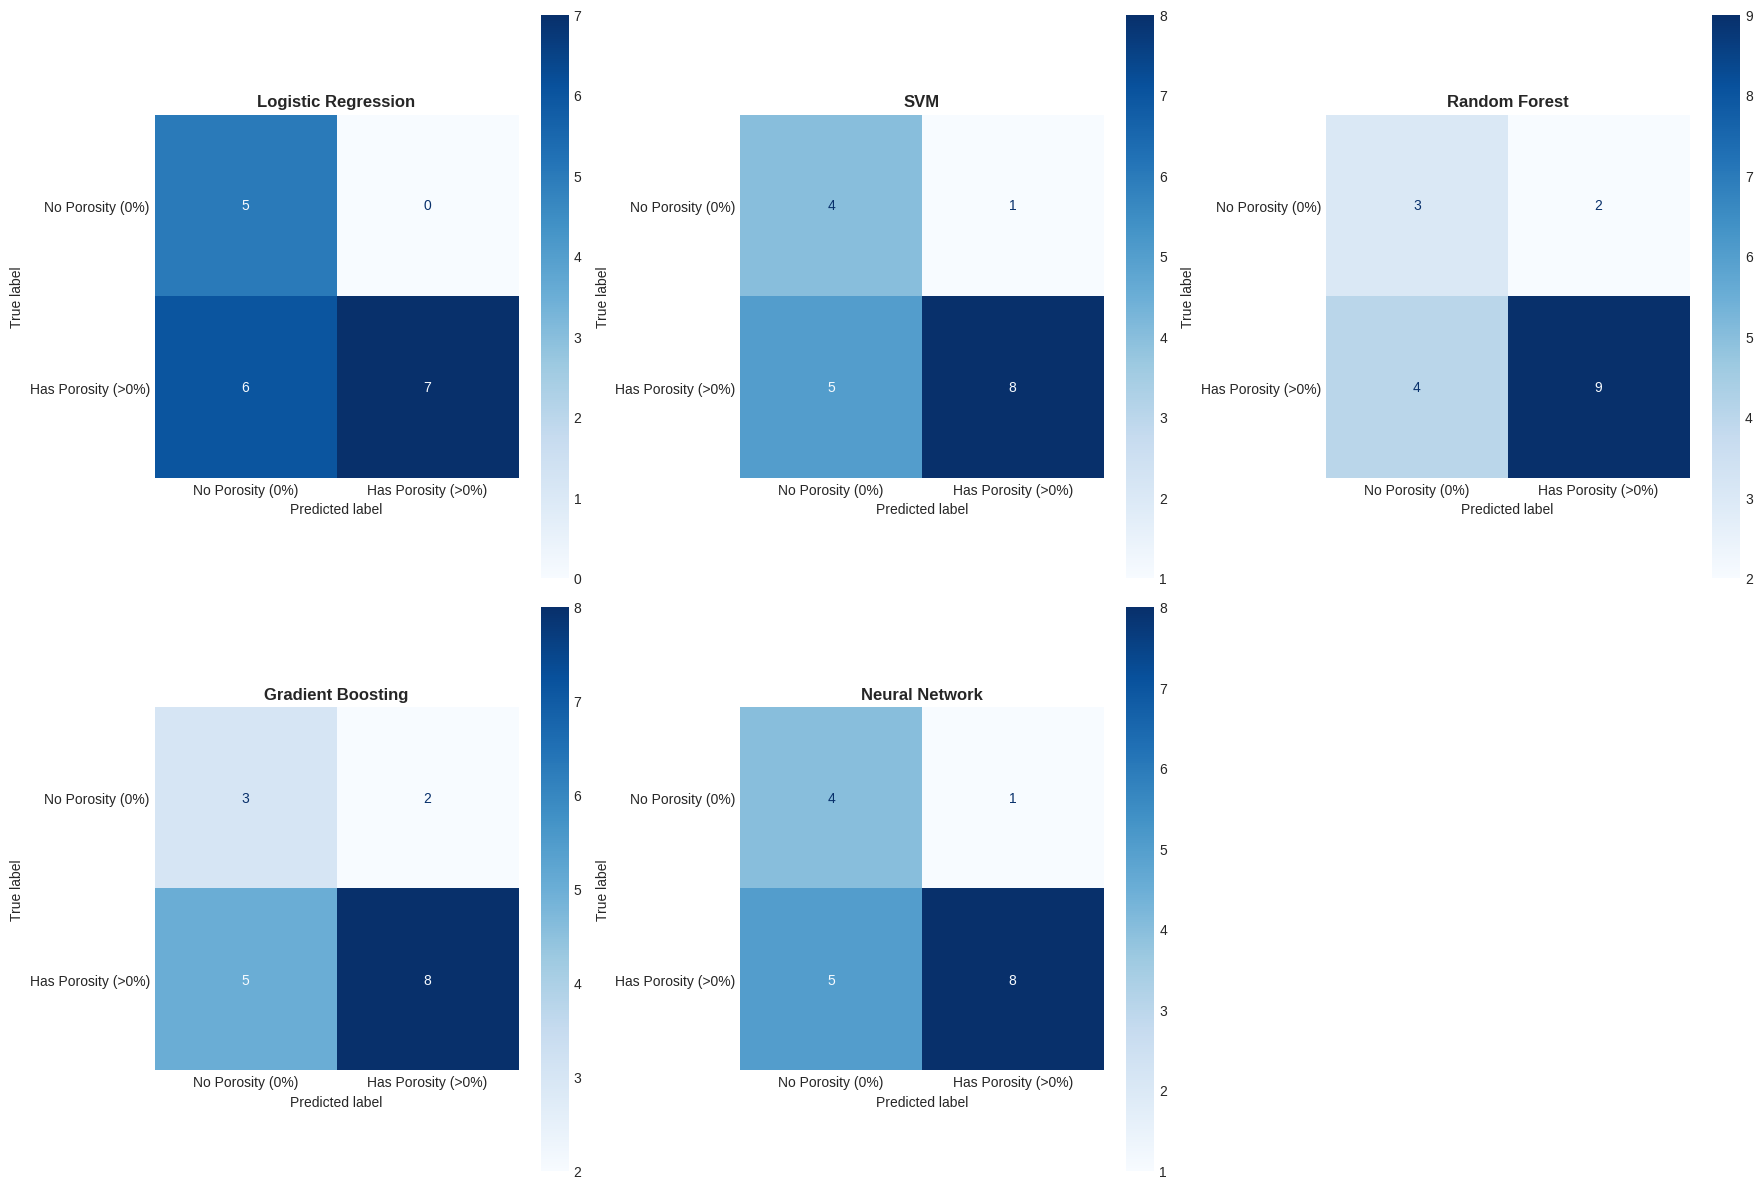

In [11]:
# confusion matrices

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for idx, model_name in enumerate(models.keys()):
    y_test_pred = best_models[model_name].predict(X_test)

    cm = confusion_matrix(y_test, y_test_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(ax=axes[idx], cmap='Blues', values_format='d')
    axes[idx].set_title(f'{model_name}', fontsize=12, fontweight='bold')
    axes[idx].grid(False)

# Remove empty subplot
axes[-1].remove()

plt.tight_layout()
plt.savefig('confusion_matrices_binary.png', dpi=300, bbox_inches='tight')
plt.show()
 

# # 10. ROC Curves

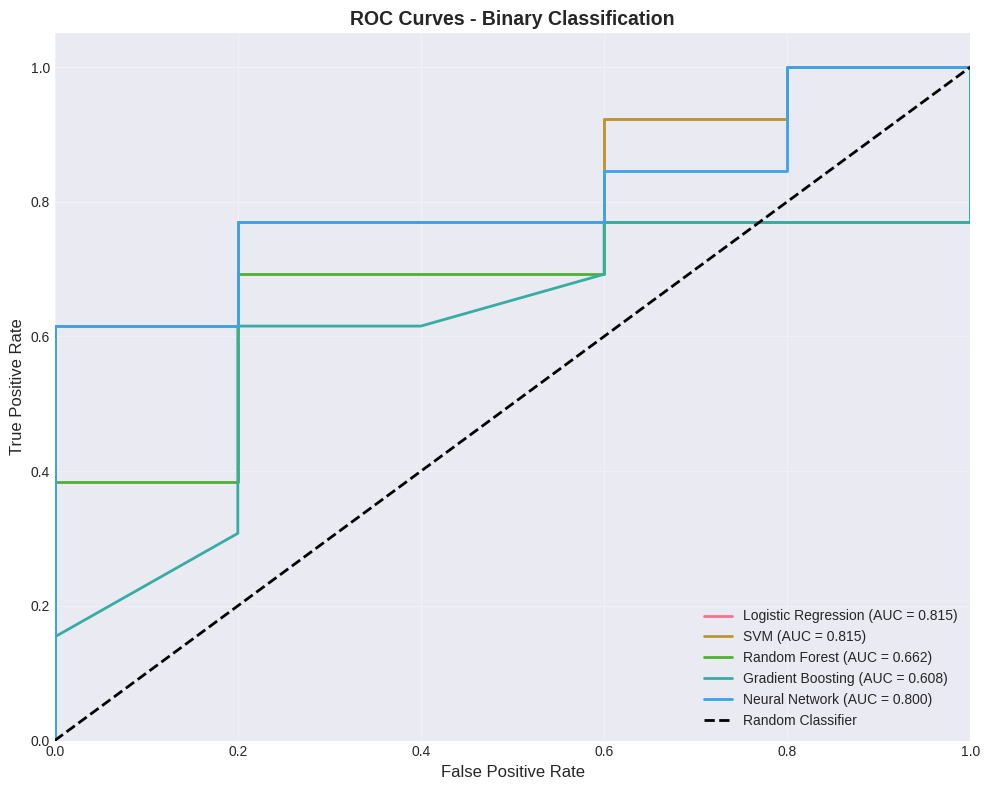

In [12]:
fig, ax = plt.subplots(figsize=(10, 8))

for model_name in models.keys():
    y_test_proba = best_models[model_name].predict_proba(X_test)[:, 1]

    fpr, tpr, _ = roc_curve(y_test, y_test_proba)
    roc_auc = roc_auc_score(y_test, y_test_proba)

    ax.plot(fpr, tpr, linewidth=2, label=f'{model_name} (AUC = {roc_auc:.3f})')

ax.plot([0, 1], [0, 1], 'k--', linewidth=2, label='Random Classifier')
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('ROC Curves - Binary Classification', fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('roc_curves_binary.png', dpi=300, bbox_inches='tight')
plt.show()

# ## 11. Feature Importance (for tree models)

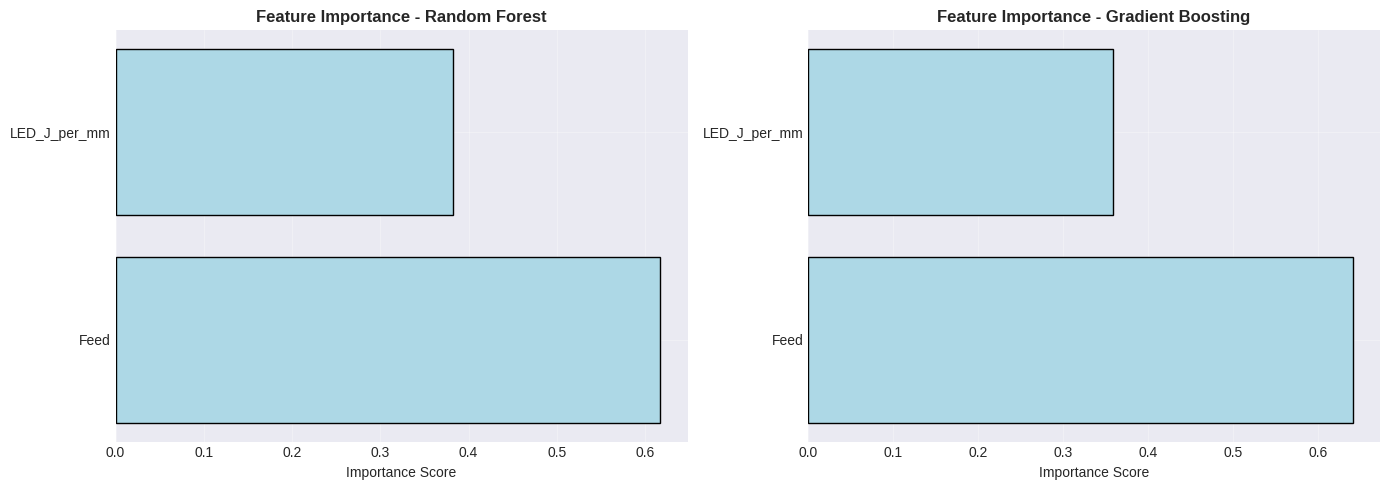

In [13]:
tree_models = ['Random Forest', 'Gradient Boosting']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for idx, model_name in enumerate(tree_models):
    if model_name in best_models:
        # Extract model from pipeline
        model = best_models[model_name].named_steps[model_name.lower().replace(' ', '_').replace('gradient_boosting', 'gb').replace('random_forest', 'rf')]

        if hasattr(model, 'feature_importances_'):
            importances = model.feature_importances_
            feature_names = X.columns
            sorted_indices = np.argsort(importances)[::-1]

            axes[idx].barh(range(len(importances)), importances[sorted_indices], color='lightblue', edgecolor='black')
            axes[idx].set_yticks(range(len(importances)))
            axes[idx].set_yticklabels(feature_names[sorted_indices])
            axes[idx].set_title(f'Feature Importance - {model_name}', fontsize=12, fontweight='bold')
            axes[idx].set_xlabel('Importance Score')
            axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('feature_importance_binary.png', dpi=300, bbox_inches='tight')
plt.show()


# ## 12. Save Results and Best Model

In [14]:
# Save results table
results_df.to_csv('porosity_binary_classification_results.csv', index=True)
print("\nResults saved to 'porosity_binary_classification_results.csv'")

# Save best model
best_model_file = f'BestClassifier_{best_model_name.replace(" ", "")}_binary.pkl'
joblib.dump(best_models[best_model_name], best_model_file)
print(f"Best model saved to '{best_model_file}'")


Results saved to 'porosity_binary_classification_results.csv'
Best model saved to 'BestClassifier_RandomForest_binary.pkl'


 ## 13. Key Improvements Summary

In [15]:
print(f"\n{'='*80}")
print("KEY IMPROVEMENTS IMPLEMENTED")
print(f"{'='*80}")
print("✓ Physics-Informed Feature: Heat Input = Power / (Speed × Feed)")
print("✓ Binary Classification: Porosity > 0% (1) vs Porosity = 0% (0)")
print(f"✓ Class Distribution: {class_counts[0]} samples (0%) vs {class_counts[1]} samples (>0%)")
print("✓ SMOTE Applied: Inside cross-validation pipeline (correct implementation)")
print(f"✓ Best Model: {best_model_name}")
print(f"✓ Test Accuracy: {summary_df.loc[best_model_name, 'accuracy_test']:.4f}")
print(f"✓ ROC-AUC: {summary_df.loc[best_model_name, 'roc_auc_test']:.4f}")
print(f"{'='*80}")


KEY IMPROVEMENTS IMPLEMENTED
✓ Physics-Informed Feature: Heat Input = Power / (Speed × Feed)
✓ Binary Classification: Porosity > 0% (1) vs Porosity = 0% (0)
✓ Class Distribution: 23 samples (0%) vs 66 samples (>0%)
✓ SMOTE Applied: Inside cross-validation pipeline (correct implementation)
✓ Best Model: Random Forest
✓ Test Accuracy: 0.6667
✓ ROC-AUC: 0.6615
